# ML from Scratch - 11 - DBSCAN

## Importing

In [138]:
import importlib
import my_dbscan

importlib.reload(my_dbscan)
from my_dbscan import DBSCAN

## Synthetic Data

In [139]:
from sklearn.datasets import make_moons
import numpy as np

np.random.seed(42)

X, labels = make_moons(1000, noise=0.05, random_state=42)

X[:5], labels[:5]

(array([[-0.02137124,  0.40618608],
        [ 0.97670045, -0.45832306],
        [ 0.90405882, -0.37651952],
        [ 0.37736316, -0.39703717],
        [-0.84192557,  0.53058695]]),
 array([1, 1, 1, 1, 0]))

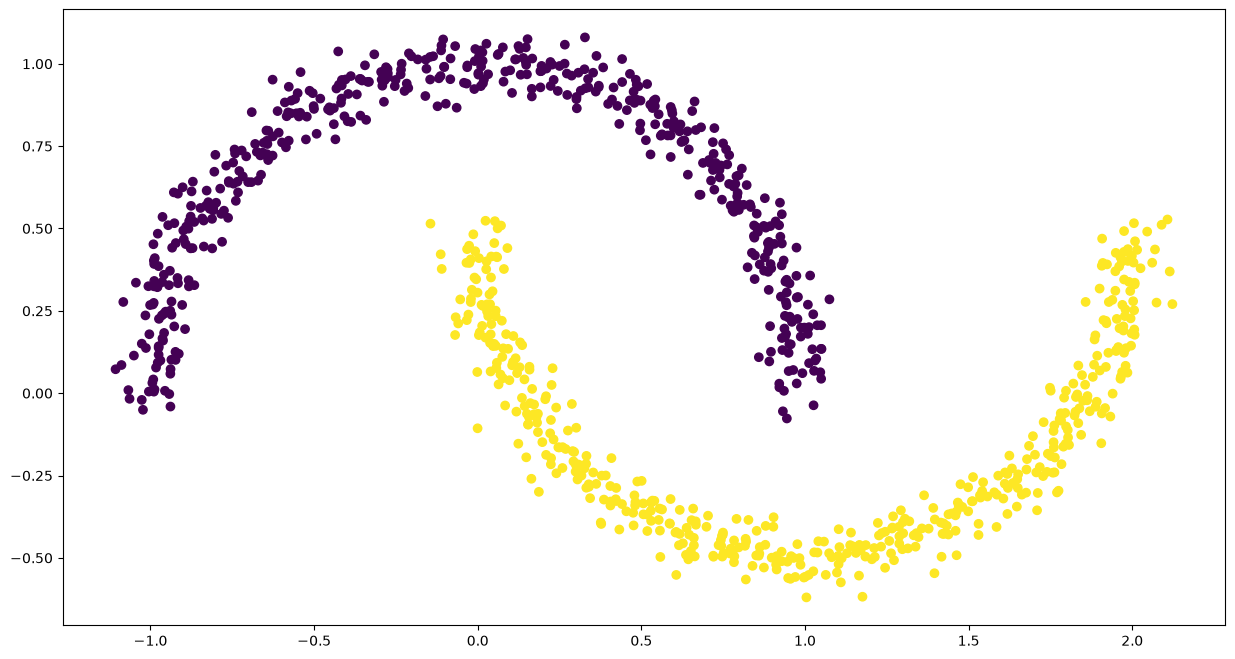

In [140]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))

plt.scatter(X[:, 0], X[:, 1], c=labels)

plt.show()

In [151]:
model = DBSCAN(epsilon=0.2, min_samples=5)
model.fit(X)

In [152]:
from sklearn.metrics import adjusted_rand_score

labels_pred = model.fit_predict(X)

adjusted_rand_score(labels, labels_pred)

[4, 8, 8, 8, 22, 8, 4, 4, 11, 21, 8, 21, 4, 11, 11, 11, 16, 11, 8, 16, 4, 21, 16, 4, 21, 21, 21, 11, 11, 11, 16, 21, 4, 22, 22, 21, 8, 4, 11, 21, 16, 21, 16, 11, 16, 16, 11, 4, 22, 8, 4, 11, 16, 4, 21, 21, 4, 21, 21, 8, 16, 21, 4, 21, 4, 8, 8, 11, 21, 4, 21, 22, 4, 8, 16, 16, 8, 21, 4, 16, 8, 21, 16, 21, 16, 4, 11, 8, 8, 16, 16, 22, 4, 21, 8, 22, 8, 21, 21, 11, 8, 16, 11, 16, 4, 4, 4, 11, 21, 11, 4, 8, 11, 8, 21, 22, 21, 11, 4, 16, 11, 22, 8, 16, 16, 4, 4, 22, 11, 8, 4, 11, 16, 11, 4, 21, 21, 21, 21, 21, 21, 21, 8, 16, 11, 11, 8, 16, 11, 16, 8, 21, 11, 22, 11, 22, 16, 8, 21, 11, 4, 8, 8, 4, 11, 8, 16, 8, 16, 16, 16, 22, 21, 11, 22, 16, 16, 16, 8, 8, 22, 8, 22, 4, 11, 21, 16, 22, 11, 8, 11, 11, 8, 21, 21, 22, 16, 21, 4, 21, 21, 4, 8, 4, 11, 4, 21, 11, 22, 8, 21, 21, 11, 8, 8, 16, 8, 16, 11, 8, 16, 8, 11, 21, 11, 21, 4, 16, 11, 4, 16, 11, 22, 4, 21, 21, 21, 11, 21, 16, 21, 21, 4, 8, 16, 21, 22, 21, 21, 16, 21, 11, 8, 11, 22, 16, 4, 11, 11, 21, 8, 22, 21, 16, 16, 11, 8, 22, 4, 22, 22, 21,

0.3513702738823199

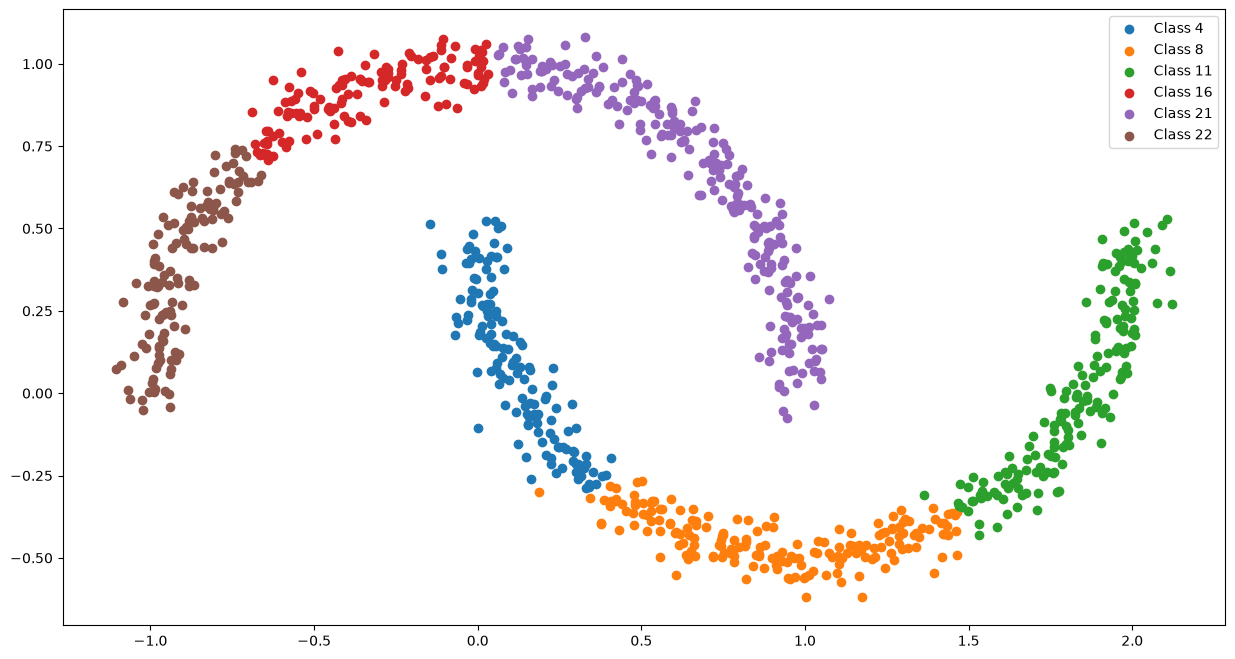

In [153]:
plt.figure(figsize=(15,8))

classes = np.unique(labels_pred)

for label in classes:
    plt.scatter(X[labels_pred == label, 0], X[labels_pred == label, 1], label=f"Class {label}")

plt.legend()
plt.show()

## Tabular Playground - July 2022

In [34]:
import pandas as pd

df = pd.read_csv('../data/tabular_playground_jul_2022/data.csv').set_index('id')

df.head()

,f_00,f_01,f_02,f_03,f_04,f_05,f_06,f_07,f_08,f_09,...,f_19,f_20,f_21,f_22,f_23,f_24,f_25,f_26,f_27,f_28
id,,,,,,,,,,,,,,,,,,,,,
0,-0.389420,-0.912791,0.648951,0.589045,-0.830817,0.733624,2.258560,2,13,14,...,-0.478412,-0.757002,-0.763635,-1.090369,1.142641,-0.884274,1.137896,1.309073,1.463002,0.813527
1,-0.689249,-0.453954,0.654175,0.995248,-1.653020,0.863810,-0.090651,2,3,6,...,-0.428791,-0.089908,-1.784204,-0.839474,0.459685,1.759412,-0.275422,-0.852168,0.562457,-2.680541
2,0.809079,0.324568,-1.170602,-0.624491,0.105448,0.783948,1.988301,5,11,5,...,-0.413534,-1.602377,1.190984,3.267116,-0.088322,-2.168635,-0.974989,1.335763,-1.110655,-3.630723
3,-0.500923,0.229049,0.264109,0.231520,0.415012,-1.221269,0.138850,6,2,13,...,0.619283,1.287801,0.532837,1.036631,-2.041828,1.440490,-1.900191,-0.630771,-0.050641,0.238333
4,-0.671268,-1.039533,-0.270155,-1.830264,-0.290108,-1.852809,0.781898,8,7,5,...,-1.628830,-0.434948,0.322505,0.284326,-2.438365,1.473930,-1.044684,1.602686,-0.405263,-1.987263


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 98000 entries, 0 to 97999
Data columns (total 29 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_00    98000 non-null  float64
 1   f_01    98000 non-null  float64
 2   f_02    98000 non-null  float64
 3   f_03    98000 non-null  float64
 4   f_04    98000 non-null  float64
 5   f_05    98000 non-null  float64
 6   f_06    98000 non-null  float64
 7   f_07    98000 non-null  int64  
 8   f_08    98000 non-null  int64  
 9   f_09    98000 non-null  int64  
 10  f_10    98000 non-null  int64  
 11  f_11    98000 non-null  int64  
 12  f_12    98000 non-null  int64  
 13  f_13    98000 non-null  int64  
 14  f_14    98000 non-null  float64
 15  f_15    98000 non-null  float64
 16  f_16    98000 non-null  float64
 17  f_17    98000 non-null  float64
 18  f_18    98000 non-null  float64
 19  f_19    98000 non-null  float64
 20  f_20    98000 non-null  float64
 21  f_21    98000 non-null  float64
 22  f_22    9

### Model Training

#### My Model

In [ ]:
from sklearn.metrics import silhouette_score

model = DBSCAN()

labels = model.fit_predict(df)

silhouette_score(df, labels)

NameError: name 'KMeans' is not defined

##### Tuning n_clusters

In [ ]:
rng_clusters = range(2, 11, 2)

best_score = 0
best_n = 0

for n in rng_clusters:
    model = DBSCAN()
    labels = model.fit_predict(df[:9800])
    score = silhouette_score(df[:9800], labels)

    if score > best_score:
        best_score = score
        best_n = n

    print(f'Silhouette score at n = {n} = {score}')

model = KMeans(n_clusters=best_n)
labels = model.fit_predict(df)

print(f'best score = {silhouette_score(df, labels)} at n = {best_n}')

Silhouette score at n = 2 = 0.17778583867297468
Silhouette score at n = 4 = 0.12599227810880073
Silhouette score at n = 6 = 0.12158113220982349
Silhouette score at n = 8 = 0.11781283973438184
Silhouette score at n = 10 = 0.1031142488026648
best score = 0.17652067720387318 at n = 2


#### Scikit-Learn Model

In [ ]:
from sklearn.cluster import KMeans as KMeans_sklearn

model_sklearn = KMeans_sklearn(n_clusters=2)

labels_sklearn = model_sklearn.fit_predict(df)

silhouette_score(df, labels_sklearn)

0.1763659732609836

### Submission

In [ ]:
submission = pd.DataFrame(labels, index=df.index, columns=['Predicted'])

submission.index.name = 'Id'

submission.to_csv('../data/tabular_playground_jul_2022/submissions/submission_kmeans_my_model.csv')

In [ ]:
submission_sklearn = pd.DataFrame(labels_sklearn, index=df.index, columns=['Predicted'])

submission_sklearn.index.name = 'Id'

submission_sklearn.to_csv('../data/tabular_playground_jul_2022/submissions/submission_kmeans_sklearn.csv')

Kaggle Score for my model: `0.11271` (adjusted rand index)

Kaggle Score for SciKit-Learn model: `0.11293` (adjusted rand index)